# Latest GW Player Picker Dashboard

Use this notebook to shortlist players by position, inspect predicted points, and generate plots you can share with your league group.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append(str(Path('../..').resolve()))
from latest_gw_tools import load_latest_outputs, load_gw_outputs
from squad_selection import get_best_11, get_best_11_noadj, get_owner_dict

sns.set_theme(style='whitegrid')
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 100)

In [2]:
# Leave TARGET_GW as None to auto-load latest available GW output.
TARGET_GW = 7
TOP_N = 20
BACKTEST_YEAR = 26
EXPORT_FIGURES = False
FIG_DIR = Path('..') / 'figures'

if EXPORT_FIGURES:
    FIG_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
if TARGET_GW is None:
    latest_gw, pred_simple, pred_full, fixture_difficulty = load_latest_outputs(predictions_dir='../predictions', fixture_dir='../fixture_difficulty')
else:
    latest_gw = TARGET_GW
    pred_simple, pred_full, fixture_difficulty = load_gw_outputs(TARGET_GW, predictions_dir='../predictions', fixture_dir='../fixture_difficulty')

print(f'Loaded GW: {latest_gw}')
print(f'Players in simple output: {len(pred_simple):,}')
print(f'Players in full output: {len(pred_full):,}')

Loaded GW: 7
Players in simple output: 669
Players in full output: 669


In [4]:
df = pred_simple.copy()
if 'predicted_points_adj' not in df.columns:
    df['predicted_points_adj'] = df['predicted_points']

owner_dict = get_owner_dict()
owner_name_map = {str(int(k)): v for k, v in owner_dict.items()}
df['owner_name'] = df['owner'].fillna(-1).astype(int).astype(str).map(owner_name_map).fillna('Free Agent')

# Combine duplicate player rows (e.g., double gameweeks) into one row per player/team/position/owner.
group_cols = ['full_name', 'team', 'position', 'owner_name']
for col in ['predicted_points', 'predicted_points_adj', 'fixture_diff_index']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

agg_dict = {
    'predicted_points': 'sum',
    'predicted_points_adj': 'sum',
}
if 'fixture_diff_index' in df.columns:
    agg_dict['fixture_diff_index'] = 'mean'

df = (
    df.groupby(group_cols, as_index=False)
    .agg(agg_dict)
)

# --- Multi-GW horizon means: mean predicted points (adjusted) over the next 3/6
# GWs starting at latest_gw. A blank GW for a player is excluded from their
# average (not counted as zero) -- matches the horizon methodology in WORKFLOW.md.
predictions_dir = Path('..') / 'predictions'

def load_horizon_mean_adj(start_gw, n_gws, predictions_dir=predictions_dir):
    frames = []
    for gw in range(start_gw, start_gw + n_gws):
        path = predictions_dir / f'predicted_gw{gw}_simple.csv'
        if not path.exists():
            break
        gw_df = pd.read_csv(path)
        if 'predicted_points_adj' not in gw_df.columns:
            gw_df['predicted_points_adj'] = gw_df['predicted_points']
        # Combine double-gameweek duplicates within this GW before averaging across GWs.
        gw_df = (
            gw_df.groupby(['full_name', 'team', 'position'], as_index=False)
            [['predicted_points_adj']].sum()
        )
        frames.append(gw_df)
    if not frames:
        return pd.DataFrame(columns=['full_name', 'team', 'position', 'predicted_points_adj'])
    return (
        pd.concat(frames, ignore_index=True)
        .groupby(['full_name', 'team', 'position'], as_index=False)
        .mean(numeric_only=True)
    )

horizon_3gw = load_horizon_mean_adj(latest_gw, 3).rename(columns={'predicted_points_adj': 'predicted_points_adj_3gw'})
horizon_6gw = load_horizon_mean_adj(latest_gw, 6).rename(columns={'predicted_points_adj': 'predicted_points_adj_6gw'})

df = df.merge(horizon_3gw, on=['full_name', 'team', 'position'], how='left')
df = df.merge(horizon_6gw, on=['full_name', 'team', 'position'], how='left')

rank_col = 'predicted_points_adj'
df_sorted = df.sort_values(rank_col, ascending=False).reset_index(drop=True)
df_sorted.head(10)

,full_name,team,position,owner_name,predicted_points,predicted_points_adj,fixture_diff_index,predicted_points_adj_3gw,predicted_points_adj_6gw
0,erling_haaland,Man City,FWD,Rory D,5.387943,8.081914,1.500000,5.335134,5.157632
1,rayan_cherki,Man City,MID,Marcus,5.057083,5.237240,1.035625,4.554646,4.516560
2,riccardo_calafiori,Arsenal,DEF,Richard,3.915191,5.208948,1.330445,4.062788,3.415225
3,charalampos_kostoulas,Brighton,FWD,Lucas,3.431009,5.146513,1.500000,3.941257,3.732966
4,jay_dasilva,Coventry City,DEF,Free Agent,3.366293,5.049439,1.500000,4.304398,3.739046
5,lewis_hall,Newcastle,DEF,Marcus,3.555427,4.926880,1.385735,3.711721,3.264140
6,david_raya_martin,Arsenal,GK,Doug,3.397351,4.898506,1.441860,3.845064,3.127406
7,antoine_semenyo,Man City,MID,Dave,4.662374,4.828469,1.035625,4.199152,4.164038
8,gabriel_dos_santos_magalhaes,Arsenal,DEF,Doug,3.607770,4.799941,1.330445,3.743777,3.147061
9,thierno_barry,Everton,FWD,Will,3.847698,4.783083,1.243103,3.892770,3.782414


In [5]:
## Position Shortlists

In [6]:
show_cols = ['full_name', 'team', 'owner_name', 'predicted_points', 'predicted_points_adj',
             'predicted_points_adj_3gw', 'predicted_points_adj_6gw', 'fixture_diff_index']
position_lists = {}

for pos in ['GK', 'DEF', 'MID', 'FWD']:
    pos_df = (
        df_sorted
        .query('position == @pos')
        .loc[:, show_cols]
        .head(TOP_N)
        .reset_index(drop=True)
    )
    position_lists[pos] = pos_df
    print(f'\nTop {TOP_N} {pos}')
    display(pos_df)


Top 20 GK


,full_name,team,owner_name,predicted_points,predicted_points_adj,predicted_points_adj_3gw,predicted_points_adj_6gw,fixture_diff_index
0,david_raya_martin,Arsenal,Doug,3.397351,4.898506,3.845064,3.127406,1.441860
1,carl_rushworth,Coventry City,Will,3.136612,4.376667,4.230778,3.477019,1.395349
2,antonin_kinsky,Spurs,Tobias,2.899108,4.348662,2.977766,3.106990,1.500000
3,dorde_petrovic,Bournemouth,Rory B,2.733201,4.068019,3.178140,3.262891,1.488372
4,james_trafford,Leeds,Arthur,3.248438,3.928344,4.029070,3.909457,1.209302
5,gianluigi_donnarumma,Man City,Lucas,3.403382,3.640828,3.099980,3.449552,1.069767
6,konstantinos_tzolakis,Hull City,Rory D,2.989238,3.475858,2.780686,2.496824,1.162791
7,caoimhin_kelleher,Brentford,Dave,3.066643,3.423230,3.518319,3.060700,1.116279
8,lukas_hornicek,Newcastle,Doug,2.908668,3.382172,2.886120,2.609909,1.162791
9,bart_verbruggen,Brighton,Tobias,3.318622,3.241445,2.868422,2.643321,0.976744



Top 20 DEF


,full_name,team,owner_name,predicted_points,predicted_points_adj,predicted_points_adj_3gw,predicted_points_adj_6gw,fixture_diff_index
0,riccardo_calafiori,Arsenal,Richard,3.915191,5.208948,4.062788,3.415225,1.330445
1,jay_dasilva,Coventry City,Free Agent,3.366293,5.049439,4.304398,3.739046,1.500000
2,lewis_hall,Newcastle,Marcus,3.555427,4.926880,3.711721,3.264140,1.385735
3,gabriel_dos_santos_magalhaes,Arsenal,Doug,3.607770,4.799941,3.743777,3.147061,1.330445
4,sven_botman,Newcastle,Rory D,3.365151,4.663208,3.513080,3.089453,1.385735
5,jan_paul_van_hecke,Spurs,Richard,3.259001,4.573726,3.330969,3.411640,1.403413
6,bobby_thomas,Coventry City,Free Agent,2.985868,4.478802,3.817958,3.316496,1.500000
7,james_justin,Leeds,Dave,3.269877,4.294614,3.774639,3.863494,1.313387
8,jayden_bogle,Leeds,Dave,3.195155,4.196476,3.688383,3.775207,1.313387
9,gabriel_gudmundsson,Leeds,Free Agent,3.080863,4.046366,3.556447,3.640166,1.313387



Top 20 MID


,full_name,team,owner_name,predicted_points,predicted_points_adj,predicted_points_adj_3gw,predicted_points_adj_6gw,fixture_diff_index
0,rayan_cherki,Man City,Marcus,5.057083,5.237240,4.554646,4.516560,1.035625
1,antoine_semenyo,Man City,Dave,4.662374,4.828469,4.199152,4.164038,1.035625
2,pascal_gross,Brighton,Tobias,4.601405,4.782239,4.106659,4.043160,1.039300
3,bukayo_saka,Arsenal,Arthur,4.568537,4.747475,4.403605,4.110694,1.039167
4,kiernan_dewsbury_hall,Everton,Richard,4.605609,4.736834,4.220607,4.219786,1.028492
5,john_mcginn,Aston Villa,Free Agent,4.222283,4.478492,3.745161,3.810402,1.060680
6,johan_manzambi,Aston Villa,Dave,4.119886,4.369881,3.654335,3.717993,1.060680
7,harvey_barnes,Newcastle,Richard,4.207344,4.226858,4.068646,3.632597,1.004638
8,martin_odegaard,Arsenal,Doug,3.715550,3.861079,3.581412,3.343190,1.039167
9,emiliano_buendia_stati,Aston Villa,Free Agent,3.619716,3.839361,3.210685,3.266615,1.060680



Top 20 FWD


,full_name,team,owner_name,predicted_points,predicted_points_adj,predicted_points_adj_3gw,predicted_points_adj_6gw,fixture_diff_index
0,erling_haaland,Man City,Rory D,5.387943,8.081914,5.335134,5.157632,1.500000
1,charalampos_kostoulas,Brighton,Lucas,3.431009,5.146513,3.941257,3.732966,1.500000
2,thierno_barry,Everton,Will,3.847698,4.783083,3.892770,3.782414,1.243103
3,joao_pedro_junqueira_de_jesus,Chelsea,Tobias,3.707396,4.611818,3.827636,3.281017,1.243951
4,oli_mcburnie,Hull City,Tobias,3.584258,4.520904,4.652682,4.051403,1.261322
5,nicolas_jackson,Aston Villa,Lucas,4.316034,4.479142,5.079934,5.009478,1.037791
6,emersonn_correia_da_silva,Ipswich Town,Dave,3.086740,3.802432,2.984246,2.896842,1.231860
7,francisco_evanilson_de_lima_barbosa,Bournemouth,Richard,3.877231,3.678920,3.152801,3.850190,0.948853
8,dominic_calvert_lewin,Leeds,Arthur,3.540884,3.484852,3.490405,3.591241,0.984176
9,dominic_solanke_mitchell,Spurs,Doug,3.416532,3.470597,4.280832,3.823228,1.015824


In [7]:
show_cols = ['full_name', 'team', 'position', 'owner_name', 'predicted_points', 'predicted_points_adj',
             'predicted_points_adj_3gw', 'predicted_points_adj_6gw', 'fixture_diff_index']
positions = ['GK', 'DEF', 'MID', 'FWD']

for pos in positions:
    doug_pos = (
        df_sorted
        .query('position == @pos and owner_name == "Doug"')
        .loc[:, show_cols]
    )

    free_agent_pos = (
        df_sorted
        .query('position == @pos and owner_name == "Free Agent"')
        .loc[:, show_cols]
        .head(20)
    )

    combined_pos = pd.concat([doug_pos, free_agent_pos], ignore_index=True)

    print(f'\n{pos}: Doug + Top Free Agents')
    display(combined_pos)



GK: Doug + Top Free Agents


,full_name,team,position,owner_name,predicted_points,predicted_points_adj,predicted_points_adj_3gw,predicted_points_adj_6gw,fixture_diff_index
0,david_raya_martin,Arsenal,GK,Doug,3.397351,4.898506,3.845064,3.127406,1.441860
1,lukas_hornicek,Newcastle,GK,Doug,2.908668,3.382172,2.886120,2.609909,1.162791
2,walter_benitez,Crystal Palace,GK,Free Agent,2.779931,1.389966,2.445908,2.844581,0.500000
3,christian_walton,Ipswich Town,GK,Free Agent,2.510925,1.255462,2.364941,2.681240,0.500000
4,kepa_arrizabalaga_revuelta,Arsenal,GK,Free Agent,0.486941,0.702101,0.551111,0.448250,1.441860
5,illan_meslier,Arsenal,GK,Free Agent,0.486941,0.702101,0.551111,0.448250,1.441860
6,nick_pope,Newcastle,GK,Free Agent,0.486663,0.565887,0.482890,0.436676,1.162791
7,guglielmo_vicario,Spurs,GK,Free Agent,0.369018,0.553527,0.379030,0.395479,1.500000
8,geronimo_rulli,Man City,GK,Free Agent,0.516042,0.552045,0.470039,0.523043,1.069767
9,michele_di_gregorio,Bournemouth,GK,Free Agent,0.370207,0.551006,0.430473,0.441952,1.488372



DEF: Doug + Top Free Agents

,full_name,team,position,owner_name,predicted_points,predicted_points_adj,predicted_points_adj_3gw,predicted_points_adj_6gw,fixture_diff_index
0,gabriel_dos_santos_magalhaes,Arsenal,DEF,Doug,3.607770,4.799941,3.743777,3.147061,1.330445
1,micky_van_de_ven,Spurs,DEF,Doug,1.707568,2.396424,1.745276,1.787544,1.403413
2,andrew_robertson,Spurs,DEF,Doug,1.618991,2.272114,1.654743,1.694819,1.403413
3,nico_o'reilly,Man City,DEF,Doug,2.115175,2.164646,2.051102,2.156114,1.023389
4,abdukodir_khusanov,Man City,DEF,Doug,0.881554,0.902172,0.854850,0.898616,1.023389
5,jay_dasilva,Coventry City,DEF,Free Agent,3.366293,5.049439,4.304398,3.739046,1.500000
6,bobby_thomas,Coventry City,DEF,Free Agent,2.985868,4.478802,3.817958,3.316496,1.500000
7,gabriel_gudmundsson,Leeds,DEF,Free Agent,3.080863,4.046366,3.556447,3.640166,1.313387
8,ethan_pinnock,Coventry City,DEF,Free Agent,2.684822,4.027233,3.433018,2.982115,1.500000
9,nico_elvedi,Leeds,DEF,Free Agent,2.502014,3.286113,2.888243,2.956232,1.313387



MID: Doug + Top Free Agents


,full_name,team,position,owner_name,predicted_points,predicted_points_adj,predicted_points_adj_3gw,predicted_points_adj_6gw,fixture_diff_index
0,martin_odegaard,Arsenal,MID,Doug,3.715550,3.861079,3.581412,3.343190,1.039167
1,jaidon_anthony,Brentford,MID,Doug,3.686127,3.669030,3.487173,3.104195,0.995362
2,alex_iwobi,Fulham,MID,Doug,3.433193,2.758742,3.239293,3.201343,0.803550
3,james_mcatee,Nott'm Forest,MID,Doug,3.123549,2.061682,2.525991,2.685280,0.660045
4,marcus_rashford,Man Utd,MID,Doug,2.127773,1.386467,1.943993,1.940278,0.651604
5,john_mcginn,Aston Villa,MID,Free Agent,4.222283,4.478492,3.745161,3.810402,1.060680
6,emiliano_buendia_stati,Aston Villa,MID,Free Agent,3.619716,3.839361,3.210685,3.266615,1.060680
7,savio_moreira_de_oliveira,Spurs,MID,Free Agent,3.716815,3.799987,3.828529,3.592690,1.022377
8,sandro_tonali,Spurs,MID,Free Agent,3.303399,3.377320,3.402688,3.193080,1.022377
9,james_garner,Everton,MID,Free Agent,3.280342,3.373807,3.006124,3.005539,1.028492



FWD: Doug + Top Free Agents


,full_name,team,position,owner_name,predicted_points,predicted_points_adj,predicted_points_adj_3gw,predicted_points_adj_6gw,fixture_diff_index
0,dominic_solanke_mitchell,Spurs,FWD,Doug,3.416532,3.470597,4.280832,3.823228,1.015824
1,kai_havertz,Arsenal,FWD,Doug,3.171291,2.401807,2.870653,3.116543,0.757359
2,omar_marmoush,Spurs,FWD,Doug,2.299399,2.335785,2.881091,2.573113,1.015824
3,sidiki_cherif,Coventry City,FWD,Free Agent,2.733177,2.375597,2.805465,2.883384,0.869171
4,danny_welbeck,Chelsea,FWD,Free Agent,1.466296,1.824001,1.513852,1.297661,1.243951
5,georginio_rutter,Brighton,FWD,Free Agent,1.155204,1.732807,1.327003,1.256872,1.500000
6,chuba_akpom,Ipswich Town,FWD,Free Agent,0.989149,1.218493,0.956305,0.928296,1.231860
7,ellis_simms,Coventry City,FWD,Free Agent,1.327279,1.153632,1.362384,1.400222,0.869171
8,robinio_vaz,Hull City,FWD,Free Agent,0.810416,1.022195,1.051991,0.916039,1.261322
9,rodrigo_muniz_carvalho,Fulham,FWD,Free Agent,1.034706,0.942790,0.953346,1.044702,0.911167


In [8]:
# A compact shortlist view you can screenshot/share.
shortlist = pd.concat(
    [
        position_lists[pos].assign(position=pos)
        for pos in ['GK', 'DEF', 'MID', 'FWD']
    ],
    ignore_index=True,
)

shortlist = shortlist[[
    'position', 'full_name', 'team', 'owner_name',
    'predicted_points', 'predicted_points_adj',
    'predicted_points_adj_3gw', 'predicted_points_adj_6gw',
    'fixture_diff_index'
 ]]
shortlist.head(40)

,position,full_name,team,owner_name,predicted_points,predicted_points_adj,predicted_points_adj_3gw,predicted_points_adj_6gw,fixture_diff_index
0,GK,david_raya_martin,Arsenal,Doug,3.397351,4.898506,3.845064,3.127406,1.441860
1,GK,carl_rushworth,Coventry City,Will,3.136612,4.376667,4.230778,3.477019,1.395349
2,GK,antonin_kinsky,Spurs,Tobias,2.899108,4.348662,2.977766,3.106990,1.500000
3,GK,dorde_petrovic,Bournemouth,Rory B,2.733201,4.068019,3.178140,3.262891,1.488372
4,GK,james_trafford,Leeds,Arthur,3.248438,3.928344,4.029070,3.909457,1.209302
5,GK,gianluigi_donnarumma,Man City,Lucas,3.403382,3.640828,3.099980,3.449552,1.069767
6,GK,konstantinos_tzolakis,Hull City,Rory D,2.989238,3.475858,2.780686,2.496824,1.162791
7,GK,caoimhin_kelleher,Brentford,Dave,3.066643,3.423230,3.518319,3.060700,1.116279
8,GK,lukas_hornicek,Newcastle,Doug,2.908668,3.382172,2.886120,2.609909,1.162791
9,GK,bart_verbruggen,Brighton,Tobias,3.318622,3.241445,2.868422,2.643321,0.976744


In [9]:
## Team Selection Helpers

In [10]:
formation_adj, best_11_adj = get_best_11(df_sorted)
formation_raw, best_11_raw = get_best_11_noadj(df_sorted)

print(f'Best XI (adj) formation: {formation_adj}')
display(best_11_adj[['full_name', 'position', 'team', 'owner_name', 'predicted_points', 'predicted_points_adj']])

print(f'Best XI (raw) formation: {formation_raw}')
display(best_11_raw[['full_name', 'position', 'team', 'owner_name', 'predicted_points']])

Best XI (adj) formation: {'GK': 1, 'DEF': 4, 'MID': 3, 'FWD': 3}


,full_name,position,team,owner_name,predicted_points,predicted_points_adj
8,erling_haaland,FWD,Man City,Rory D,5.387943,8.081914
5,rayan_cherki,MID,Man City,Marcus,5.057083,5.237240
1,riccardo_calafiori,DEF,Arsenal,Richard,3.915191,5.208948
9,charalampos_kostoulas,FWD,Brighton,Lucas,3.431009,5.146513
2,jay_dasilva,DEF,Coventry City,Free Agent,3.366293,5.049439
3,lewis_hall,DEF,Newcastle,Marcus,3.555427,4.926880
0,david_raya_martin,GK,Arsenal,Doug,3.397351,4.898506
6,antoine_semenyo,MID,Man City,Dave,4.662374,4.828469
4,gabriel_dos_santos_magalhaes,DEF,Arsenal,Doug,3.607770,4.799941
10,thierno_barry,FWD,Everton,Will,3.847698,4.783083


Best XI (raw) formation: {'GK': 1, 'DEF': 3, 'MID': 5, 'FWD': 2}


,full_name,position,team,owner_name,predicted_points
9,erling_haaland,FWD,Man City,Rory D,5.387943
4,rayan_cherki,MID,Man City,Marcus,5.057083
5,antoine_semenyo,MID,Man City,Dave,4.662374
10,igor_thiago_nascimento_rodrigues,FWD,Brentford,Rory B,4.606859
6,kiernan_dewsbury_hall,MID,Everton,Richard,4.605609
7,pascal_gross,MID,Brighton,Tobias,4.601405
8,bruno_borges_fernandes,MID,Man Utd,Lucas,4.577162
1,james_tarkowski,DEF,Everton,Marcus,4.036335
2,riccardo_calafiori,DEF,Arsenal,Richard,3.915191
3,maxim_de_cuyper,DEF,Brighton,Will,3.838582


In [11]:
doug_pool = df_sorted.query('owner_name == "Doug"').copy()
doug_formation, doug_best_11 = get_best_11(doug_pool)

print(f"Doug Best XI formation: {doug_formation['DEF']}-{doug_formation['MID']}-{doug_formation['FWD']}")
display(
    doug_best_11[
        ['full_name', 'position', 'team', 'predicted_points', 'predicted_points_adj', 'fixture_diff_index']
    ].sort_values(['position', 'predicted_points_adj'], ascending=[True, False]).reset_index(drop=True)
)

bench_key_cols = ['full_name', 'team', 'position']
bench_keys = set(
    tuple(row) for row in doug_best_11[bench_key_cols].drop_duplicates().itertuples(index=False, name=None)
)
bench_players = (
    doug_pool[
        ~doug_pool[bench_key_cols].apply(tuple, axis=1).isin(bench_keys)
    ][['full_name', 'position', 'team', 'predicted_points', 'predicted_points_adj', 'fixture_diff_index']]
    .sort_values('predicted_points_adj', ascending=False)
    .reset_index(drop=True)
)

print('Doug Bench Players:')
display(bench_players)

Doug Best XI formation: 4-3-3


,full_name,position,team,predicted_points,predicted_points_adj,fixture_diff_index
0,gabriel_dos_santos_magalhaes,DEF,Arsenal,3.607770,4.799941,1.330445
1,micky_van_de_ven,DEF,Spurs,1.707568,2.396424,1.403413
2,andrew_robertson,DEF,Spurs,1.618991,2.272114,1.403413
3,nico_o'reilly,DEF,Man City,2.115175,2.164646,1.023389
4,dominic_solanke_mitchell,FWD,Spurs,3.416532,3.470597,1.015824
5,kai_havertz,FWD,Arsenal,3.171291,2.401807,0.757359
6,omar_marmoush,FWD,Spurs,2.299399,2.335785,1.015824
7,david_raya_martin,GK,Arsenal,3.397351,4.898506,1.441860
8,martin_odegaard,MID,Arsenal,3.715550,3.861079,1.039167
9,jaidon_anthony,MID,Brentford,3.686127,3.669030,0.995362


Doug Bench Players:


,full_name,position,team,predicted_points,predicted_points_adj,fixture_diff_index
0,lukas_hornicek,GK,Newcastle,2.908668,3.382172,1.162791
1,james_mcatee,MID,Nott'm Forest,3.123549,2.061682,0.660045
2,marcus_rashford,MID,Man Utd,2.127773,1.386467,0.651604
3,abdukodir_khusanov,DEF,Man City,0.881554,0.902172,1.023389


In [12]:
owner_summary_rows = []
fa_formation = None
fa_best_11 = pd.DataFrame()

for owner_name in sorted(df_sorted['owner_name'].unique()):
    if owner_name == 'Free Agent':
        continue
    owner_df = df_sorted.query('owner_name == @owner_name').copy()
    if owner_df.empty:
        continue
    owner_formation, owner_best_11 = get_best_11(owner_df)
    owner_summary_rows.append({
        'owner_name': owner_name,
        'formation': f"{owner_formation['DEF']}-{owner_formation['MID']}-{owner_formation['FWD']}",
        'predicted_points_adj_sum': owner_best_11['predicted_points_adj'].sum(),
        'predicted_points_sum': owner_best_11['predicted_points'].sum(),
    })

# Add and show the best XI that can be built from free agents only.
free_agent_df = df_sorted.query('owner_name == "Free Agent"').copy()
if not free_agent_df.empty:
    fa_formation, fa_best_11 = get_best_11(free_agent_df)
    owner_summary_rows.append({
        'owner_name': 'Free Agent XI',
        'formation': f"{fa_formation['DEF']}-{fa_formation['MID']}-{fa_formation['FWD']}",
        'predicted_points_adj_sum': fa_best_11['predicted_points_adj'].sum(),
        'predicted_points_sum': fa_best_11['predicted_points'].sum(),
    })

owner_summary = pd.DataFrame(owner_summary_rows).sort_values('predicted_points_adj_sum', ascending=False)
display(owner_summary)

if fa_best_11.empty:
    print('No Free Agent XI available for this GW.')
else:
    print(f"Free Agent XI formation: {fa_formation['DEF']}-{fa_formation['MID']}-{fa_formation['FWD']}")
    display(
        fa_best_11[
            ['full_name', 'position', 'team', 'predicted_points', 'predicted_points_adj', 'fixture_diff_index']
        ].sort_values(['position', 'predicted_points_adj'], ascending=[True, False]).reset_index(drop=True)
    )

,owner_name,formation,predicted_points_adj_sum,predicted_points_sum
1,Dave,3-5-2,41.346113,38.614943
10,Free Agent XI,4-5-1,40.236369,35.773508
5,Richard,3-5-2,39.781396,40.717536
7,Rory D,5-3-2,38.817554,34.451349
4,Marcus,4-4-2,37.917469,39.265509
8,Tobias,4-4-2,37.872504,37.122336
2,Doug,4-3-3,35.028670,32.168947
3,Lucas,5-3-2,33.356815,33.838102
9,Will,4-4-2,33.269682,36.178271
6,Rory B,3-5-2,32.285071,33.658803


Free Agent XI formation: 4-5-1


,full_name,position,team,predicted_points,predicted_points_adj,fixture_diff_index
0,jay_dasilva,DEF,Coventry City,3.366293,5.049439,1.500000
1,bobby_thomas,DEF,Coventry City,2.985868,4.478802,1.500000
2,gabriel_gudmundsson,DEF,Leeds,3.080863,4.046366,1.313387
3,ethan_pinnock,DEF,Coventry City,2.684822,4.027233,1.500000
4,sidiki_cherif,FWD,Coventry City,2.733177,2.375597,0.869171
5,walter_benitez,GK,Crystal Palace,2.779931,1.389966,0.500000
6,john_mcginn,MID,Aston Villa,4.222283,4.478492,1.060680
7,emiliano_buendia_stati,MID,Aston Villa,3.619716,3.839361,1.060680
8,savio_moreira_de_oliveira,MID,Spurs,3.716815,3.799987,1.022377
9,sandro_tonali,MID,Spurs,3.303399,3.377320,1.022377


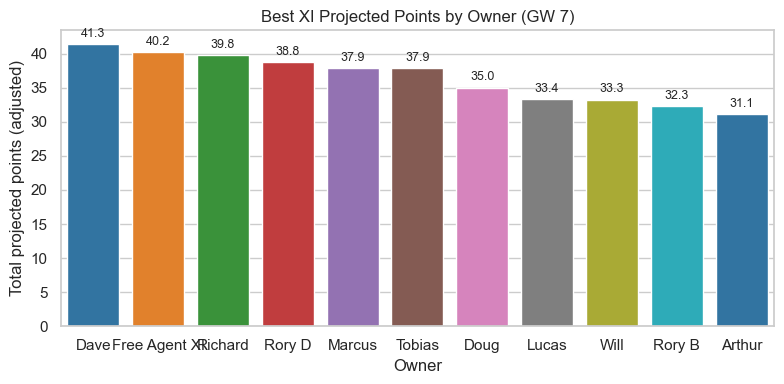

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_owner_summary = owner_summary.copy()

sns.barplot(
    data=plot_owner_summary,
    x='owner_name',
    y='predicted_points_adj_sum',
    hue='owner_name',
    legend=False,
    ax=ax,
    palette='tab10',
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=9)

ax.set_title(f'Best XI Projected Points by Owner (GW {latest_gw})')
ax.set_xlabel('Owner')
ax.set_ylabel('Total projected points (adjusted)')
plt.xticks(rotation=0)
plt.tight_layout()

if EXPORT_FIGURES:
    fig.savefig(FIG_DIR / f'owner_best_xi_gw{latest_gw}.png', dpi=200)

## Season Trajectory: Cumulative Points by Owner

In [14]:
from league_points import get_current_gw, load_owner_actual_points, load_standings, compute_expected_league_points

current_gw = get_current_gw()
actual_points_df = load_owner_actual_points()

print(f'Real current GW: {current_gw}')
display(actual_points_df.sort_values(['owner_name', 'gw']).head(10))

Real current GW: 6


,gw,owner_name,actual_points,actual_league_points,finished
2,1,Arthur,51,3,True
17,2,Arthur,40,0,True
20,3,Arthur,38,3,True
39,4,Arthur,41,0,True
43,5,Arthur,36,3,True
58,6,Arthur,27,0,True
8,1,Dave,35,0,True
11,2,Dave,23,0,True
26,3,Dave,34,0,True
33,4,Dave,45,3,True


In [15]:
END_GW = 38  # season length (league stop_event)

def load_owner_projected_points(current_gw, end_gw=END_GW, predictions_dir=Path('..') / 'predictions'):
    """Best-XI (adjusted) projected total per owner for each future GW -- repeats
    the single-GW 'Best XI by Owner' logic above (get_best_11 on each owner's pool)
    once per remaining GW, reading that GW's own prediction file each time."""
    owner_dict = get_owner_dict()
    owner_name_map = {str(int(k)): v for k, v in owner_dict.items()}

    rows = []
    for gw in range(current_gw + 1, end_gw + 1):
        path = predictions_dir / f'predicted_gw{gw}_simple.csv'
        if not path.exists():
            continue
        gw_df = pd.read_csv(path)
        if 'predicted_points_adj' not in gw_df.columns:
            gw_df['predicted_points_adj'] = gw_df['predicted_points']
        gw_df['owner_name'] = gw_df['owner'].fillna(-1).astype(int).astype(str).map(owner_name_map).fillna('Free Agent')

        for owner_name in owner_dict.values():
            owner_pool = gw_df.query('owner_name == @owner_name')
            if owner_pool.empty:
                continue
            _, owner_best_11 = get_best_11(owner_pool)
            rows.append({
                'gw': gw,
                'owner_name': owner_name,
                'projected_points': owner_best_11['predicted_points_adj'].sum(),
            })
    return pd.DataFrame(rows)

projected_points_df = load_owner_projected_points(current_gw)
projected_points_df.sort_values(['owner_name', 'gw']).head(10)

,gw,owner_name,projected_points
7,7,Arthur,31.102357
17,8,Arthur,28.821390
27,9,Arthur,29.289125
37,10,Arthur,27.373116
47,11,Arthur,28.698525
57,12,Arthur,28.034324
67,13,Arthur,27.615916
77,14,Arthur,34.590971
87,15,Arthur,30.871132
97,16,Arthur,30.779086


In [16]:
owner_names = list(get_owner_dict().values())
trajectory_rows = []

for owner_name in owner_names:
    # Real: cumulative actual points through the current (possibly live) GW -- solid.
    owner_actual = actual_points_df.query('owner_name == @owner_name').sort_values('gw')
    cumulative = 0.0
    for _, row in owner_actual.iterrows():
        cumulative += row['actual_points']
        trajectory_rows.append({'owner_name': owner_name, 'gw': row['gw'], 'cumulative_points': cumulative, 'kind': 'actual'})

    # Anchor the projected segment at the same point so the dotted line starts
    # exactly where the solid line ends (no visual gap at current_gw).
    trajectory_rows.append({'owner_name': owner_name, 'gw': current_gw, 'cumulative_points': cumulative, 'kind': 'projected'})

    # Projected: keep adding each future GW's best-XI total -- dotted.
    owner_projected = projected_points_df.query('owner_name == @owner_name').sort_values('gw')
    for _, row in owner_projected.iterrows():
        cumulative += row['projected_points']
        trajectory_rows.append({'owner_name': owner_name, 'gw': row['gw'], 'cumulative_points': cumulative, 'kind': 'projected'})

trajectory_df = pd.DataFrame(trajectory_rows)
trajectory_df.head()

,owner_name,gw,cumulative_points,kind
0,Lucas,1,29.0,actual
1,Lucas,2,84.0,actual
2,Lucas,3,110.0,actual
3,Lucas,4,152.0,actual
4,Lucas,5,195.0,actual


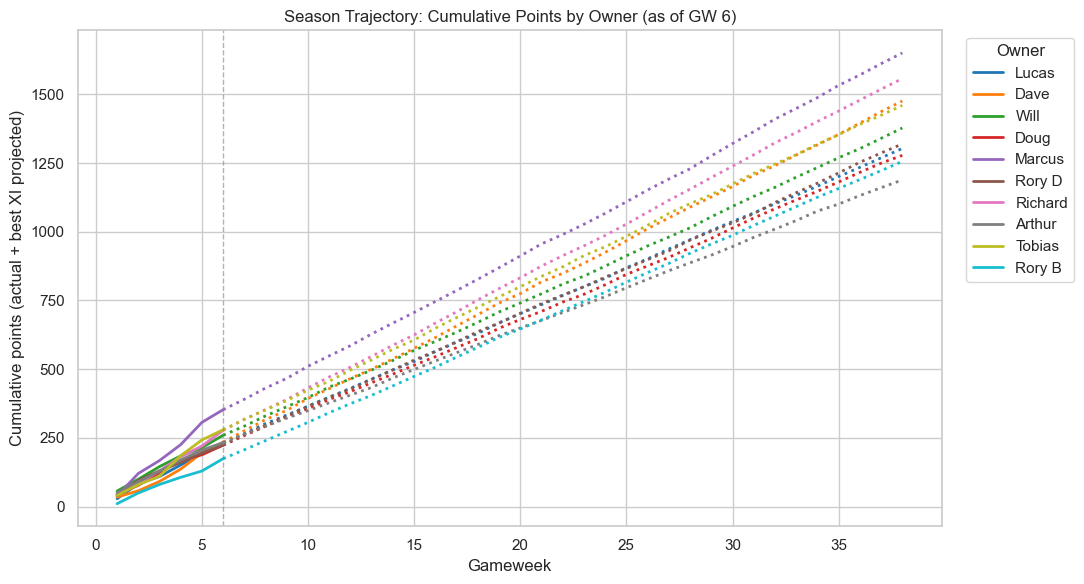

In [17]:
fig, ax = plt.subplots(figsize=(11, 6))
palette = sns.color_palette('tab10', n_colors=len(owner_names))
color_by_owner = dict(zip(owner_names, palette))

for owner_name in owner_names:
    owner_traj = trajectory_df.query('owner_name == @owner_name').sort_values('gw')
    color = color_by_owner[owner_name]
    actual_seg = owner_traj.query('kind == "actual"')
    projected_seg = owner_traj.query('kind == "projected"')
    ax.plot(actual_seg['gw'], actual_seg['cumulative_points'], color=color, linestyle='-', linewidth=2, label=owner_name)
    ax.plot(projected_seg['gw'], projected_seg['cumulative_points'], color=color, linestyle=':', linewidth=2)

ax.axvline(current_gw, color='grey', linestyle='--', linewidth=1, alpha=0.6)
ax.set_title(f'Season Trajectory: Cumulative Points by Owner (as of GW {current_gw})')
ax.set_xlabel('Gameweek')
ax.set_ylabel('Cumulative points (actual + best XI projected)')
ax.legend(title='Owner', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

if EXPORT_FIGURES:
    fig.savefig(FIG_DIR / f'season_trajectory_gw{current_gw}.png', dpi=200)

## Expected League Points: Actual vs Expected (Luck)

Each GW, rank every owner by their actual score that week (1st to last) and award a
linear share of 3 points down to 0 -- `3 * (n_owners - rank) / (n_owners - 1)` -- as if
that week were a mini round-robin against the whole league, not just your one assigned
H2H opponent. Comparing the cumulative version of this against your real cumulative H2H
league points shows whether you've been over- or under-performing your weekly form due
to a favorable/unfavorable schedule.

In [18]:
expected_points_df = compute_expected_league_points(actual_points_df)

league_points_df = expected_points_df.sort_values(['owner_name', 'gw']).copy()
league_points_df['cumulative_actual_league_points'] = league_points_df.groupby('owner_name')['actual_league_points'].cumsum()
league_points_df['cumulative_expected_league_points'] = league_points_df.groupby('owner_name')['expected_league_points'].cumsum()

display(league_points_df.head(10))

# Sanity check: derived actual_league_points (3/1/0 from comparing raw match points)
# should sum to the same cumulative total the API itself reports in standings -- but
# only through the last *finished* GW, since the live standings total doesn't yet
# include a GW that's merely started (in progress).
finished_cumulative = (
    league_points_df.query('finished')
    .groupby('owner_name')
    .tail(1)[['owner_name', 'gw', 'cumulative_actual_league_points']]
)
standings_df = load_standings()
check_df = finished_cumulative.merge(standings_df[['owner_name', 'total', 'rank']], on='owner_name').sort_values('rank')
check_df['matches_standings'] = check_df['cumulative_actual_league_points'] == check_df['total']

if not check_df['matches_standings'].all():
    print('WARNING: derived actual_league_points does not match live standings total for:')
    display(check_df.query('~matches_standings'))
else:
    print('Sanity check passed (through the last finished GW): derived actual_league_points matches live standings total for all owners.')
display(check_df)

,gw,owner_name,actual_points,actual_league_points,finished,rank,expected_league_points,cumulative_actual_league_points,cumulative_expected_league_points
2,1,Arthur,51,3,True,2.0,2.666667,3,2.666667
17,2,Arthur,40,0,True,5.0,1.666667,3,4.333333
20,3,Arthur,38,3,True,5.0,1.666667,6,6.000000
39,4,Arthur,41,0,True,7.0,1.000000,6,7.000000
43,5,Arthur,36,3,True,6.0,1.333333,9,8.333333
58,6,Arthur,27,0,True,10.0,0.000000,9,8.333333
8,1,Dave,35,0,True,8.0,0.666667,0,0.666667
11,2,Dave,23,0,True,10.0,0.000000,0,0.666667
26,3,Dave,34,0,True,7.0,1.000000,0,1.666667
33,4,Dave,45,3,True,4.0,2.000000,3,3.666667


Sanity check passed (through the last finished GW): derived actual_league_points matches live standings total for all owners.


,owner_name,gw,cumulative_actual_league_points,total,rank,matches_standings
4,Marcus,6,15,15,1,True
8,Tobias,6,15,15,2,True
5,Richard,6,12,12,3,True
1,Dave,6,9,9,4,True
3,Lucas,6,9,9,5,True
0,Arthur,6,9,9,5,True
7,Rory D,6,9,9,7,True
9,Will,6,7,7,8,True
2,Doug,6,4,4,9,True
6,Rory B,6,0,0,10,True


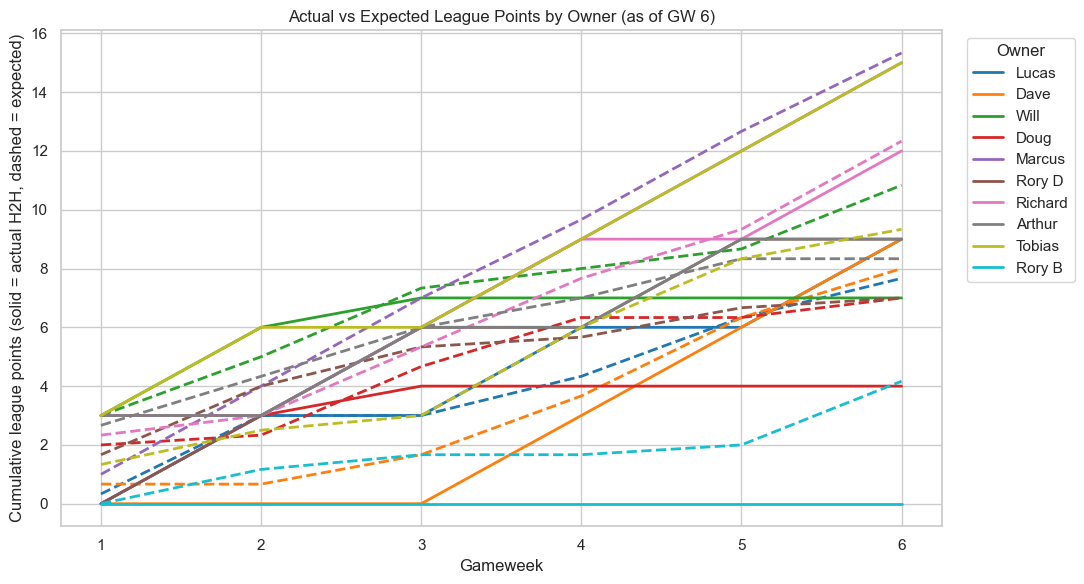

In [19]:
fig, ax = plt.subplots(figsize=(11, 6))

for owner_name in owner_names:
    owner_lp = league_points_df.query('owner_name == @owner_name').sort_values('gw')
    color = color_by_owner[owner_name]
    ax.plot(owner_lp['gw'], owner_lp['cumulative_actual_league_points'], color=color, linestyle='-', linewidth=2, label=owner_name)
    ax.plot(owner_lp['gw'], owner_lp['cumulative_expected_league_points'], color=color, linestyle='--', linewidth=2)

ax.set_title(f'Actual vs Expected League Points by Owner (as of GW {current_gw})')
ax.set_xlabel('Gameweek')
ax.set_ylabel('Cumulative league points (solid = actual H2H, dashed = expected)')
ax.legend(title='Owner', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

if EXPORT_FIGURES:
    fig.savefig(FIG_DIR / f'expected_league_points_gw{current_gw}.png', dpi=200)

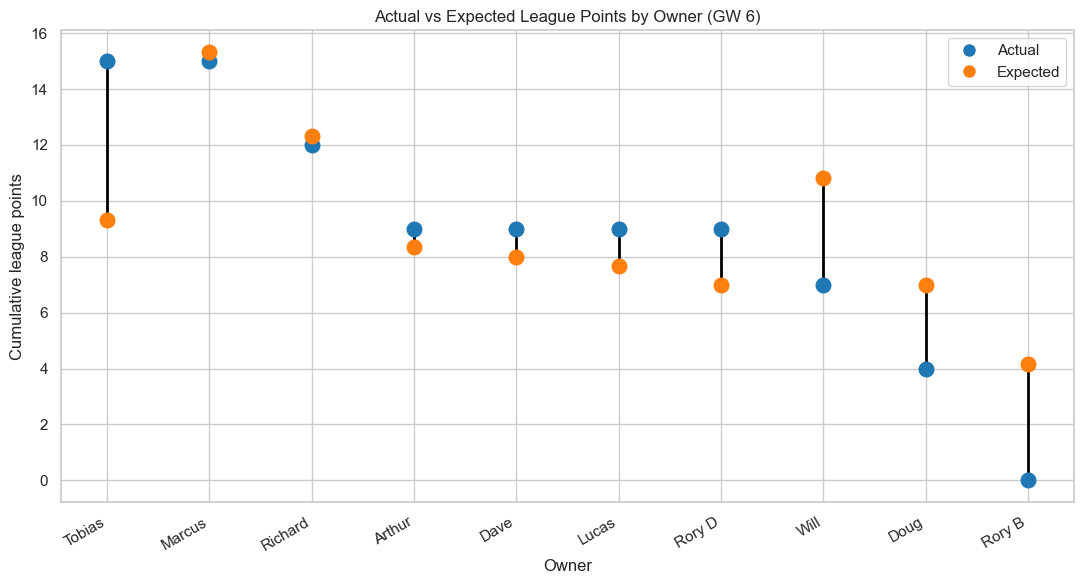

In [20]:
from matplotlib.lines import Line2D

# One row per owner: their cumulative actual/expected league points as of the most
# recent GW (current_gw, which may still be live/in-progress -- same convention as
# the trajectory chart above). Ranked by actual league points, matching the real table.
latest_lp = (
    league_points_df.groupby('owner_name').tail(1)
    .sort_values('cumulative_actual_league_points', ascending=False)
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(11, 6))
x = range(len(latest_lp))

for i, row in latest_lp.iterrows():
    ax.plot([i, i], [row['cumulative_expected_league_points'], row['cumulative_actual_league_points']],
            color='black', linewidth=2, zorder=1)

ax.scatter(x, latest_lp['cumulative_actual_league_points'], color='tab:blue', s=110, zorder=2)
ax.scatter(x, latest_lp['cumulative_expected_league_points'], color='tab:orange', s=110, zorder=2)

ax.set_xticks(list(x))
ax.set_xticklabels(latest_lp['owner_name'], rotation=30, ha='right')
ax.set_title(f'Actual vs Expected League Points by Owner (GW {current_gw})')
ax.set_xlabel('Owner')
ax.set_ylabel('Cumulative league points')

legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='tab:blue', markersize=10, label='Actual'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='tab:orange', markersize=10, label='Expected'),
]
ax.legend(handles=legend_elements, loc='upper right')
plt.tight_layout()

if EXPORT_FIGURES:
    fig.savefig(FIG_DIR / f'lollipop_expected_league_points_gw{current_gw}.png', dpi=200)

## Shareable Plots

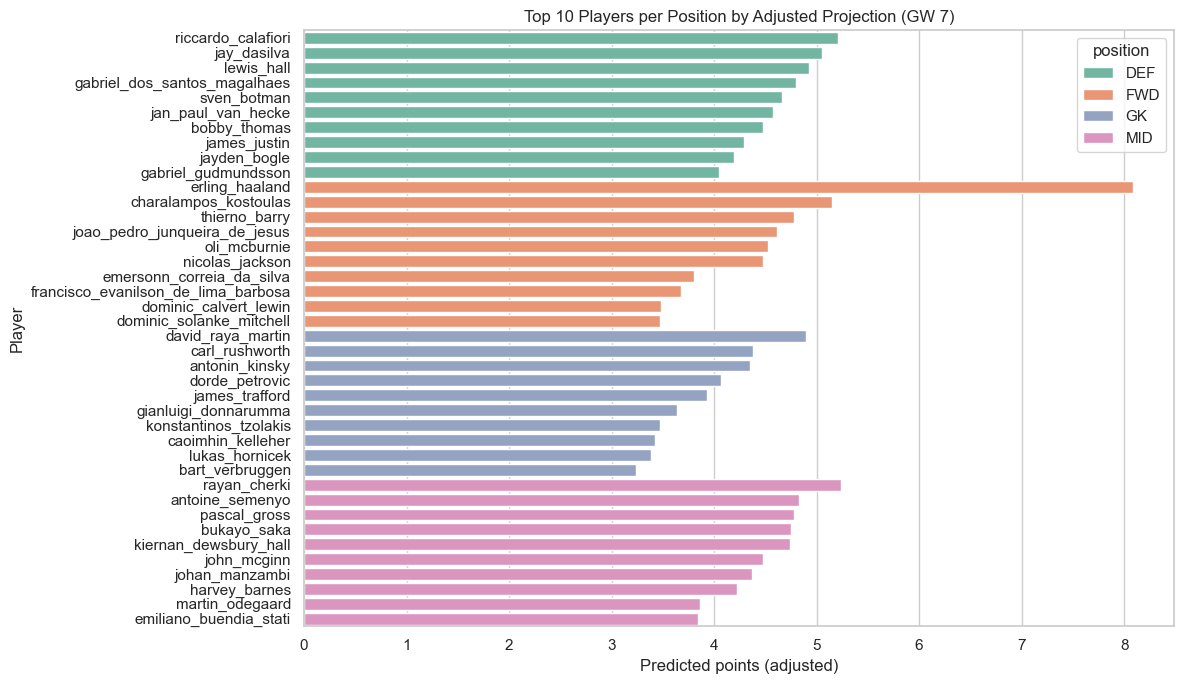

In [21]:
plot_df = (
    df_sorted
    .groupby('position', group_keys=False)
    .head(10)
    .copy()
)

fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(
    data=plot_df.sort_values(['position', 'predicted_points_adj'], ascending=[True, False]),
    x='predicted_points_adj',
    y='full_name',
    hue='position',
    dodge=False,
    ax=ax,
    palette='Set2',
)
ax.set_title(f'Top 10 Players per Position by Adjusted Projection (GW {latest_gw})')
ax.set_xlabel('Predicted points (adjusted)')
ax.set_ylabel('Player')
plt.tight_layout()

if EXPORT_FIGURES:
    fig.savefig(FIG_DIR / f'top10_by_position_gw{latest_gw}.png', dpi=200)

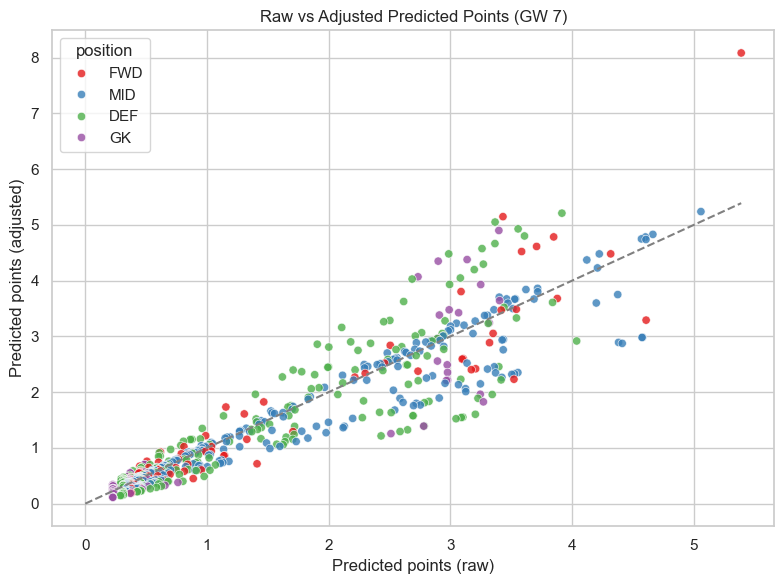

In [22]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=df_sorted,
    x='predicted_points',
    y='predicted_points_adj',
    hue='position',
    alpha=0.8,
    ax=ax,
    palette='Set1',
)
ax.plot([0, df_sorted['predicted_points'].max()], [0, df_sorted['predicted_points'].max()], linestyle='--', color='grey')
ax.set_title(f'Raw vs Adjusted Predicted Points (GW {latest_gw})')
ax.set_xlabel('Predicted points (raw)')
ax.set_ylabel('Predicted points (adjusted)')
plt.tight_layout()

if EXPORT_FIGURES:
    fig.savefig(FIG_DIR / f'raw_vs_adjusted_gw{latest_gw}.png', dpi=200)

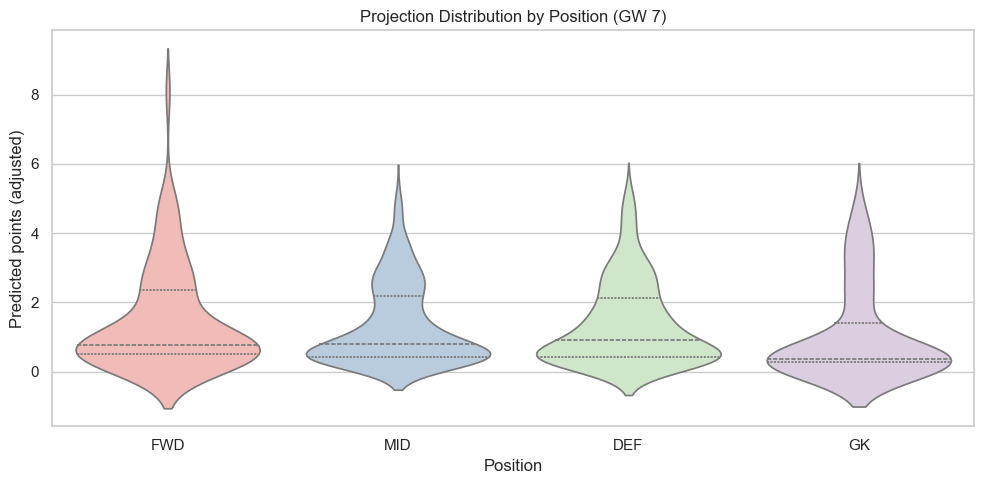

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.violinplot(
    data=df_sorted,
    x='position',
    y='predicted_points_adj',
    inner='quartile',
    hue='position',
    legend=False,
    ax=ax,
    palette='Pastel1',
)
ax.set_title(f'Projection Distribution by Position (GW {latest_gw})')
ax.set_xlabel('Position')
ax.set_ylabel('Predicted points (adjusted)')
plt.tight_layout()

if EXPORT_FIGURES:
    fig.savefig(FIG_DIR / f'distribution_by_position_gw{latest_gw}.png', dpi=200)

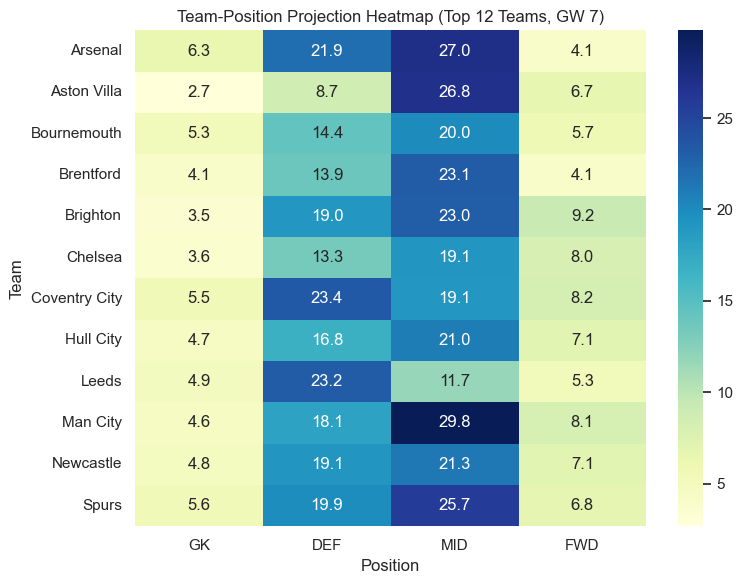

In [24]:
team_pos = (
    df_sorted
    .groupby(['team', 'position'], as_index=False)['predicted_points_adj']
    .sum()
)

team_total = team_pos.groupby('team', as_index=False)['predicted_points_adj'].sum()
top_teams = team_total.sort_values('predicted_points_adj', ascending=False).head(12)['team']
heat_df = team_pos[team_pos['team'].isin(top_teams)].pivot(index='team', columns='position', values='predicted_points_adj').fillna(0)
heat_df = heat_df[['GK', 'DEF', 'MID', 'FWD']]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(heat_df, annot=True, fmt='.1f', cmap='YlGnBu', ax=ax)
ax.set_title(f'Team-Position Projection Heatmap (Top 12 Teams, GW {latest_gw})')
ax.set_xlabel('Position')
ax.set_ylabel('Team')
plt.tight_layout()

if EXPORT_FIGURES:
    fig.savefig(FIG_DIR / f'team_position_heatmap_gw{latest_gw}.png', dpi=200)

In [25]:
share_cols = ['full_name', 'position', 'team', 'owner_name', 'predicted_points', 'predicted_points_adj',
              'predicted_points_adj_3gw', 'predicted_points_adj_6gw', 'fixture_diff_index']
share_table = df_sorted[share_cols].head(25).copy()
share_table

,full_name,position,team,owner_name,predicted_points,predicted_points_adj,predicted_points_adj_3gw,predicted_points_adj_6gw,fixture_diff_index
0,erling_haaland,FWD,Man City,Rory D,5.387943,8.081914,5.335134,5.157632,1.500000
1,rayan_cherki,MID,Man City,Marcus,5.057083,5.237240,4.554646,4.516560,1.035625
2,riccardo_calafiori,DEF,Arsenal,Richard,3.915191,5.208948,4.062788,3.415225,1.330445
3,charalampos_kostoulas,FWD,Brighton,Lucas,3.431009,5.146513,3.941257,3.732966,1.500000
4,jay_dasilva,DEF,Coventry City,Free Agent,3.366293,5.049439,4.304398,3.739046,1.500000
5,lewis_hall,DEF,Newcastle,Marcus,3.555427,4.926880,3.711721,3.264140,1.385735
6,david_raya_martin,GK,Arsenal,Doug,3.397351,4.898506,3.845064,3.127406,1.441860
7,antoine_semenyo,MID,Man City,Dave,4.662374,4.828469,4.199152,4.164038,1.035625
8,gabriel_dos_santos_magalhaes,DEF,Arsenal,Doug,3.607770,4.799941,3.743777,3.147061,1.330445
9,thierno_barry,FWD,Everton,Will,3.847698,4.783083,3.892770,3.782414,1.243103


In [26]:
if EXPORT_FIGURES:
    print(f'Saved figures to: {FIG_DIR.resolve()}')
else:
    print('Set EXPORT_FIGURES = True to save PNG charts for sharing.')

Set EXPORT_FIGURES = True to save PNG charts for sharing.


## Historical Backtest: Predicted vs Actual (All GWs)

In [27]:
import re
import sys
import requests

sys.path.append(str(Path('../..').resolve()))
from wrangle_data_funcs import clean_name

predictions_dir = Path('..') / 'predictions'
pred_files = sorted(predictions_dir.glob('predicted_gw[0-9]*.csv'))

gw_file_pairs = []
for file_path in pred_files:
    if file_path.name.endswith('_simple.csv'):
        continue
    match = re.search(r'predicted_gw(\d+)\.csv$', file_path.name)
    if match:
        gw_file_pairs.append((int(match.group(1)), file_path))

gw_file_pairs = sorted(gw_file_pairs, key=lambda x: x[0])
print(f'Found GW prediction files: {len(gw_file_pairs)}')

bootstrap = requests.get('https://fantasy.premierleague.com/api/bootstrap-static/', timeout=20).json()
name_by_element = {}
for elem in bootstrap['elements']:
    full_name = clean_name(f"{elem['first_name']}_{elem['second_name']}")
    name_by_element[elem['id']] = full_name

def load_actual_points_for_gw_from_api(gw):
    event_live = requests.get(f'https://fantasy.premierleague.com/api/event/{gw}/live/', timeout=20).json()
    rows = []
    for item in event_live.get('elements', []):
        element_id = item.get('id')
        full_name = name_by_element.get(element_id)
        if full_name is None:
            continue
        total_points = item.get('stats', {}).get('total_points', np.nan)
        rows.append({'full_name': full_name, 'actual_points': total_points})

    actual_gw_df = pd.DataFrame(rows)
    if actual_gw_df.empty:
        raise ValueError(f'No actual rows returned from FPL API for GW {gw}')

    return actual_gw_df

backtest_frames = []
skipped_gws = []
for gw, file_path in gw_file_pairs:
    pred_gw_df = pd.read_csv(file_path)
    if 'predicted_points_adj' not in pred_gw_df.columns:
        pred_gw_df['predicted_points_adj'] = pred_gw_df['predicted_points']

    try:
        actual_gw_df = load_actual_points_for_gw_from_api(gw)
    except Exception as exc:
        skipped_gws.append((gw, str(exc)))
        continue

    merged = pred_gw_df.merge(actual_gw_df, on='full_name', how='inner')
    if merged.empty:
        skipped_gws.append((gw, 'No name overlap between prediction and actual files'))
        continue

    merged['gw'] = gw
    backtest_frames.append(
        merged[['gw', 'full_name', 'position', 'team', 'predicted_points', 'predicted_points_adj', 'actual_points']]
    )

backtest_df = pd.concat(backtest_frames, ignore_index=True) if backtest_frames else pd.DataFrame()
print(f'Total merged player-GW rows: {len(backtest_df):,}')
if skipped_gws:
    print(f'Skipped GWs: {[gw for gw, _ in skipped_gws]}')

if not backtest_df.empty:
    backtest_df['error_raw'] = backtest_df['predicted_points'] - backtest_df['actual_points']
    backtest_df['error_adj'] = backtest_df['predicted_points_adj'] - backtest_df['actual_points']
    backtest_df['abs_error_raw'] = backtest_df['error_raw'].abs()
    backtest_df['abs_error_adj'] = backtest_df['error_adj'].abs()

backtest_df.head()

Found GW prediction files: 37


Total merged player-GW rows: 3,213
Skipped GWs: [7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38]


,gw,full_name,position,team,predicted_points,predicted_points_adj,actual_points,error_raw,error_adj,abs_error_raw,abs_error_adj
0,2,aaron_anselmino,DEF,Chelsea,0.782188,0.391094,0,0.782188,0.391094,0.782188,0.391094
1,2,aaron_hickey,DEF,Brentford,1.512935,3.025870,1,0.512935,2.025870,0.512935,2.025870
2,2,abdoul_ouattara,DEF,Ipswich Town,0.947001,1.894002,1,-0.052999,0.894002,0.052999,0.894002
3,2,abdukodir_khusanov,DEF,Man City,3.211374,6.422748,2,1.211374,4.422748,1.211374,4.422748
4,2,abdul_fatawu,MID,Ipswich Town,2.414172,1.984991,4,-1.585828,-2.015009,1.585828,2.015009


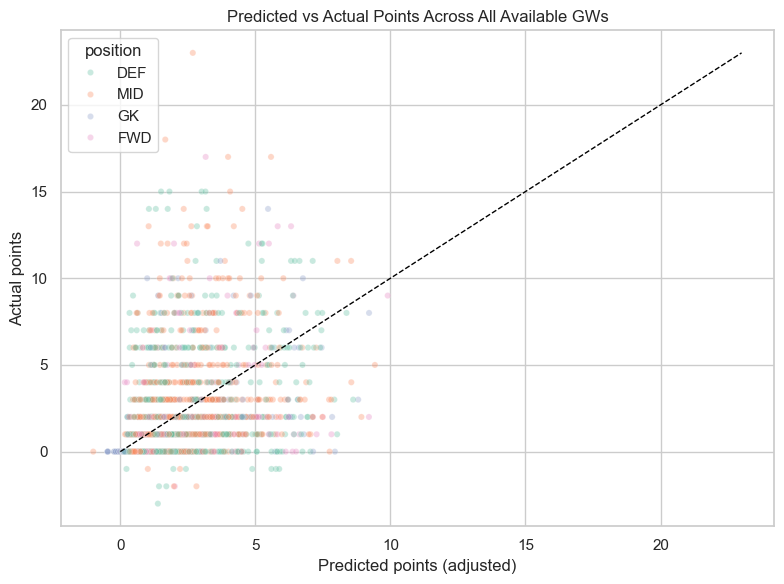

In [28]:
if backtest_df.empty:
    print('No backtest rows available. Check BACKTEST_YEAR and prediction files.')
else:
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.scatterplot(
        data=backtest_df,
        x='predicted_points_adj',
        y='actual_points',
        hue='position',
        alpha=0.35,
        s=20,
        ax=ax,
        palette='Set2',
    )

    max_axis = max(backtest_df['predicted_points_adj'].max(), backtest_df['actual_points'].max(), 1)
    ax.plot([0, max_axis], [0, max_axis], linestyle='--', color='black', linewidth=1)
    ax.set_title(f'Predicted vs Actual Points Across All Available GWs')
    ax.set_xlabel('Predicted points (adjusted)')
    ax.set_ylabel('Actual points')
    plt.tight_layout()

    if EXPORT_FIGURES:
        fig.savefig(FIG_DIR / 'pred_vs_actual_all_gws.png', dpi=200)

,gw,mae_raw,mae_adj,rmse_raw,rmse_adj,corr_adj,n_players
0,2,1.269875,1.471447,2.139009,2.495223,0.453176,609
1,3,1.241781,1.405630,1.987240,2.208180,0.492621,625
2,4,1.319584,1.302080,2.193797,2.166706,0.581621,653
3,5,1.264848,1.320265,2.169803,2.289808,0.497599,659
4,6,1.214737,1.250947,2.058566,2.140465,0.480664,667


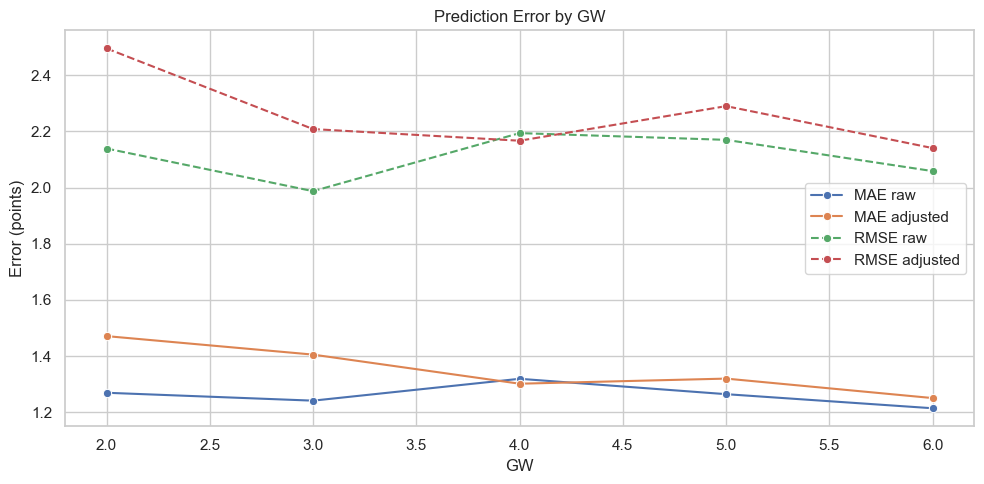

In [29]:
if backtest_df.empty:
    print('No backtest rows available. Skipping GW metric plots.')
else:
    gw_metrics = (
        backtest_df.groupby('gw', as_index=False)
        .agg(
            mae_raw=('abs_error_raw', 'mean'),
            mae_adj=('abs_error_adj', 'mean'),
            rmse_raw=('error_raw', lambda x: np.sqrt(np.mean(np.square(x)))),
            rmse_adj=('error_adj', lambda x: np.sqrt(np.mean(np.square(x)))),
            corr_adj=('predicted_points_adj', lambda x: x.corr(backtest_df.loc[x.index, 'actual_points'])),
            n_players=('full_name', 'count'),
        )
    )

    display(gw_metrics)

    fig, ax = plt.subplots(figsize=(10, 5))
    sns.lineplot(data=gw_metrics, x='gw', y='mae_raw', marker='o', label='MAE raw', ax=ax)
    sns.lineplot(data=gw_metrics, x='gw', y='mae_adj', marker='o', label='MAE adjusted', ax=ax)
    sns.lineplot(data=gw_metrics, x='gw', y='rmse_raw', marker='o', label='RMSE raw', ax=ax, linestyle='--')
    sns.lineplot(data=gw_metrics, x='gw', y='rmse_adj', marker='o', label='RMSE adjusted', ax=ax, linestyle='--')
    ax.set_title('Prediction Error by GW')
    ax.set_xlabel('GW')
    ax.set_ylabel('Error (points)')
    plt.tight_layout()

    if EXPORT_FIGURES:
        fig.savefig(FIG_DIR / 'prediction_error_by_gw.png', dpi=200)

### What Is corr_adj?

`corr_adj` is the Pearson correlation between `predicted_points_adj` and `actual_points` within each GW.

- `corr_adj` near `1.0`: your model ranked players very well that week.
- `corr_adj` near `0.0`: weak relationship between predictions and outcomes.
- `corr_adj` below `0.0`: rankings were directionally wrong that week.

This is most useful for judging ranking quality, not absolute error size.

,gw,corr_adj
0,2,0.453176
1,3,0.492621
2,4,0.581621
3,5,0.497599
4,6,0.480664


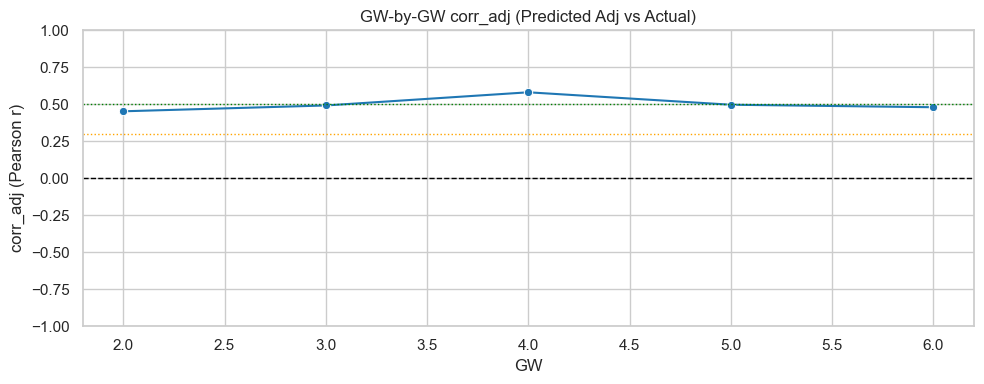

In [30]:
if backtest_df.empty:
    print('No backtest rows available. Skipping corr_adj plot.')
else:
    corr_plot_df = gw_metrics[['gw', 'corr_adj']].dropna().copy()

    fig, ax = plt.subplots(figsize=(10, 4))
    sns.lineplot(data=corr_plot_df, x='gw', y='corr_adj', marker='o', ax=ax, color='#1f77b4')
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
    ax.axhline(0.5, color='green', linestyle=':', linewidth=1)
    ax.axhline(0.3, color='orange', linestyle=':', linewidth=1)
    ax.set_ylim(-1, 1)
    ax.set_title('GW-by-GW corr_adj (Predicted Adj vs Actual)')
    ax.set_xlabel('GW')
    ax.set_ylabel('corr_adj (Pearson r)')
    plt.tight_layout()

    display(corr_plot_df)

    if EXPORT_FIGURES:
        fig.savefig(FIG_DIR / 'corr_adj_by_gw.png', dpi=200)